# The outline of "G" in Inter

These are the instructions for the uppercase G in Inter Regular (Inter 4.001, the default instance of the variable font). TrueType fonts store quadratic Bézier curves, and a run of control points with no on-curve point between them implies an on-curve point at their midpoint. Those implied points are written out below, so every curve is a plain quadratic with one control point and one end point.

Coordinates are in font units (2048 per em) with y pointing up.

In [1]:
import brushcue

# (instruction, control point, end point). "move" and "line" have no control point.
G_INSTRUCTIONS = [
    ("move", None, (789, -20)),
    ("quad", (590, -20), (440, 73)),
    ("quad", (290, 166), (206, 337.5)),
    ("quad", (122, 509), (122, 744)),
    ("quad", (122, 981), (206, 1152.5)),
    ("quad", (290, 1324), (438, 1417)),
    ("quad", (586, 1510), (777, 1510)),
    ("quad", (895, 1510), (997.5, 1475)),
    ("quad", (1100, 1440), (1181, 1375)),
    ("quad", (1262, 1310), (1315.5, 1220.5)),
    ("quad", (1369, 1131), (1389, 1023)),
    ("line", None, (1193, 1023)),
    ("quad", (1170, 1095), (1132, 1152)),
    ("quad", (1094, 1209), (1041.5, 1250)),
    ("quad", (989, 1291), (923, 1312.5)),
    ("quad", (857, 1334), (778, 1334)),
    ("quad", (647, 1334), (540, 1266.5)),
    ("quad", (433, 1199), (370, 1067.5)),
    ("quad", (307, 936), (307, 744)),
    ("quad", (307, 554), (370.5, 423)),
    ("quad", (434, 292), (543, 224)),
    ("quad", (652, 156), (789, 156)),
    ("quad", (915, 156), (1011, 209.5)),
    ("quad", (1107, 263), (1160.5, 361.5)),
    ("quad", (1214, 460), (1214, 594)),
    ("line", None, (1271, 583)),
    ("line", None, (828, 583)),
    ("line", None, (828, 749)),
    ("line", None, (1400, 749)),
    ("line", None, (1400, 586)),
    ("quad", (1400, 401), (1321, 265)),
    ("quad", (1242, 129), (1104.5, 54.5)),
    ("quad", (967, -20), (789, -20)),
]

def to_canvas(point):
    # Fonts use y up; the canvas uses y down.
    return brushcue.Point2f.from_components(point[0], -point[1])

outline = brushcue.Path.new()
for instruction, control, end in G_INSTRUCTIONS:
    if instruction == "move":
        outline = outline.move_to_point(to_canvas(end))
    elif instruction == "line":
        outline = outline.line_to_point(to_canvas(end))
    else:
        outline = outline.quadratic_bezier_to_point(to_canvas(control), to_canvas(end))

In [2]:
def solid(r, g, b, a=1.0):
    return brushcue.ProfiledColor.from_rgba_srgb(brushcue.RGBAColor.from_components(r, g, b, a))

ON_CURVE_COLOR = solid(0.15, 0.15, 0.15)
CONTROL_COLOR = solid(0.12, 0.37, 0.75)
OUTLINE_WIDTH = 6
POINT_DIAMETER = 26

painter = brushcue.Painter.new()

# Dashed lines from each control point to the two on-curve points it sits between.
control_polygon_style = brushcue.RenderStyle.brush_only(
    brushcue.Brush.dashed(solid(0.12, 0.37, 0.75, 0.6), 14, solid(0, 0, 0, 0), 10, 3)
)
previous_end = None
for instruction, control, end in G_INSTRUCTIONS:
    if instruction == "quad":
        control_polygon = (
            brushcue.Path.new()
            .move_to_point(to_canvas(previous_end))
            .line_to_point(to_canvas(control))
            .line_to_point(to_canvas(end))
        )
        painter = painter.add_path_with_render_style(
            control_polygon, control_polygon_style, brushcue.Transform2.identity().to_list()
        )
    previous_end = end

painter = painter.add_path_with_render_style(
    outline,
    brushcue.RenderStyle.brush_only(brushcue.Brush.solid(solid(0.3, 0.3, 0.3), OUTLINE_WIDTH)),
    brushcue.Transform2.identity().to_list(),
)

def add_point(painter, point, color):
    return painter.add_ellipse_with_render_style(
        to_canvas(point),
        brushcue.Vector2f.from_components(POINT_DIAMETER, POINT_DIAMETER),
        0,
        brushcue.RenderStyle.fill_only(brushcue.Fill.solid(color)),
        brushcue.Transform2.identity().to_list(),
    )

for instruction, control, end in G_INSTRUCTIONS:
    if control is not None:
        painter = add_point(painter, control, CONTROL_COLOR)
    painter = add_point(painter, end, ON_CURVE_COLOR)

In [3]:
import os
from pathlib import Path

def find_repo_root():
    for directory in (Path.cwd(), *Path.cwd().parents):
        if (directory / "writing/graphics/fonts").is_dir():
            return directory
    raise FileNotFoundError("Could not find the graphics book directory")

# BrushCue reads files relative to the working directory, so run from the
# monorepo root to load the book font stored in writing/graphics/fonts.
os.chdir(find_repo_root())
ctx = brushcue.Context()

BOOK_FONT = brushcue.Font.from_path("writing/graphics/fonts/LibertinusSerif-Regular.otf")
LABEL_SIZE = 44

def label_string(text, origin, color):
    render_style = brushcue.RenderStyle.fill_only(brushcue.Fill.solid(color))

    @brushcue.brushcue_fn
    def style_label_character(character):
        return brushcue.StyledCharacter.new(character, BOOK_FONT, LABEL_SIZE, render_style)

    characters = brushcue.String(brushcue.input_parsers.parse_string_graph(text)).to_character_list()
    return brushcue.StyledString.styled_string_from_characters_free(
        characters.to_stream().map(style_label_character).collect(),
        brushcue.Point2f.from_components(*origin),
    )

# A legend below the glyph, in the book's font.
LEGEND_Y = 150
LEGEND_ITEMS = (
    (220, "On-curve point", ON_CURVE_COLOR),
    (720, "Control point", CONTROL_COLOR),
)
LABEL_GAP = 24
for x, text, color in LEGEND_ITEMS:
    painter = add_point(painter, (x, -LEGEND_Y), color)
    # Measure the label at the origin so it can be centered beside its point.
    bounds = brushcue.Composition.painter(
        brushcue.Painter.new().add_styled_text(label_string(text, (0, 0), ON_CURVE_COLOR))
    ).bounds().execute(ctx)
    label_x = x + POINT_DIAMETER / 2 + LABEL_GAP - bounds.x
    label_y = LEGEND_Y - bounds.y - bounds.height / 2
    painter = painter.add_styled_text(label_string(text, (label_x, label_y), ON_CURVE_COLOR))

# A transparent rectangle that pads the image so points on the edge are not clipped.
MARGIN = 60
LEFT, RIGHT, TOP, BOTTOM = 122, 1400, -1510, LEGEND_Y + LABEL_SIZE
painter = painter.add_rectangle_with_render_style(
    brushcue.Point2f.from_components((LEFT + RIGHT) / 2, (TOP + BOTTOM) / 2),
    brushcue.Vector2f.from_components(RIGHT - LEFT + 2 * MARGIN, BOTTOM - TOP + 2 * MARGIN),
    0,
    brushcue.RenderStyle.fill_only(brushcue.Fill.solid(solid(1, 1, 1, 0))),
    brushcue.Transform2.identity().to_list(),
)

[wgpu] using backend Vulkan — adapter 'NVIDIA GeForce RTX 5070' (DiscreteGpu), driver 'NVIDIA'


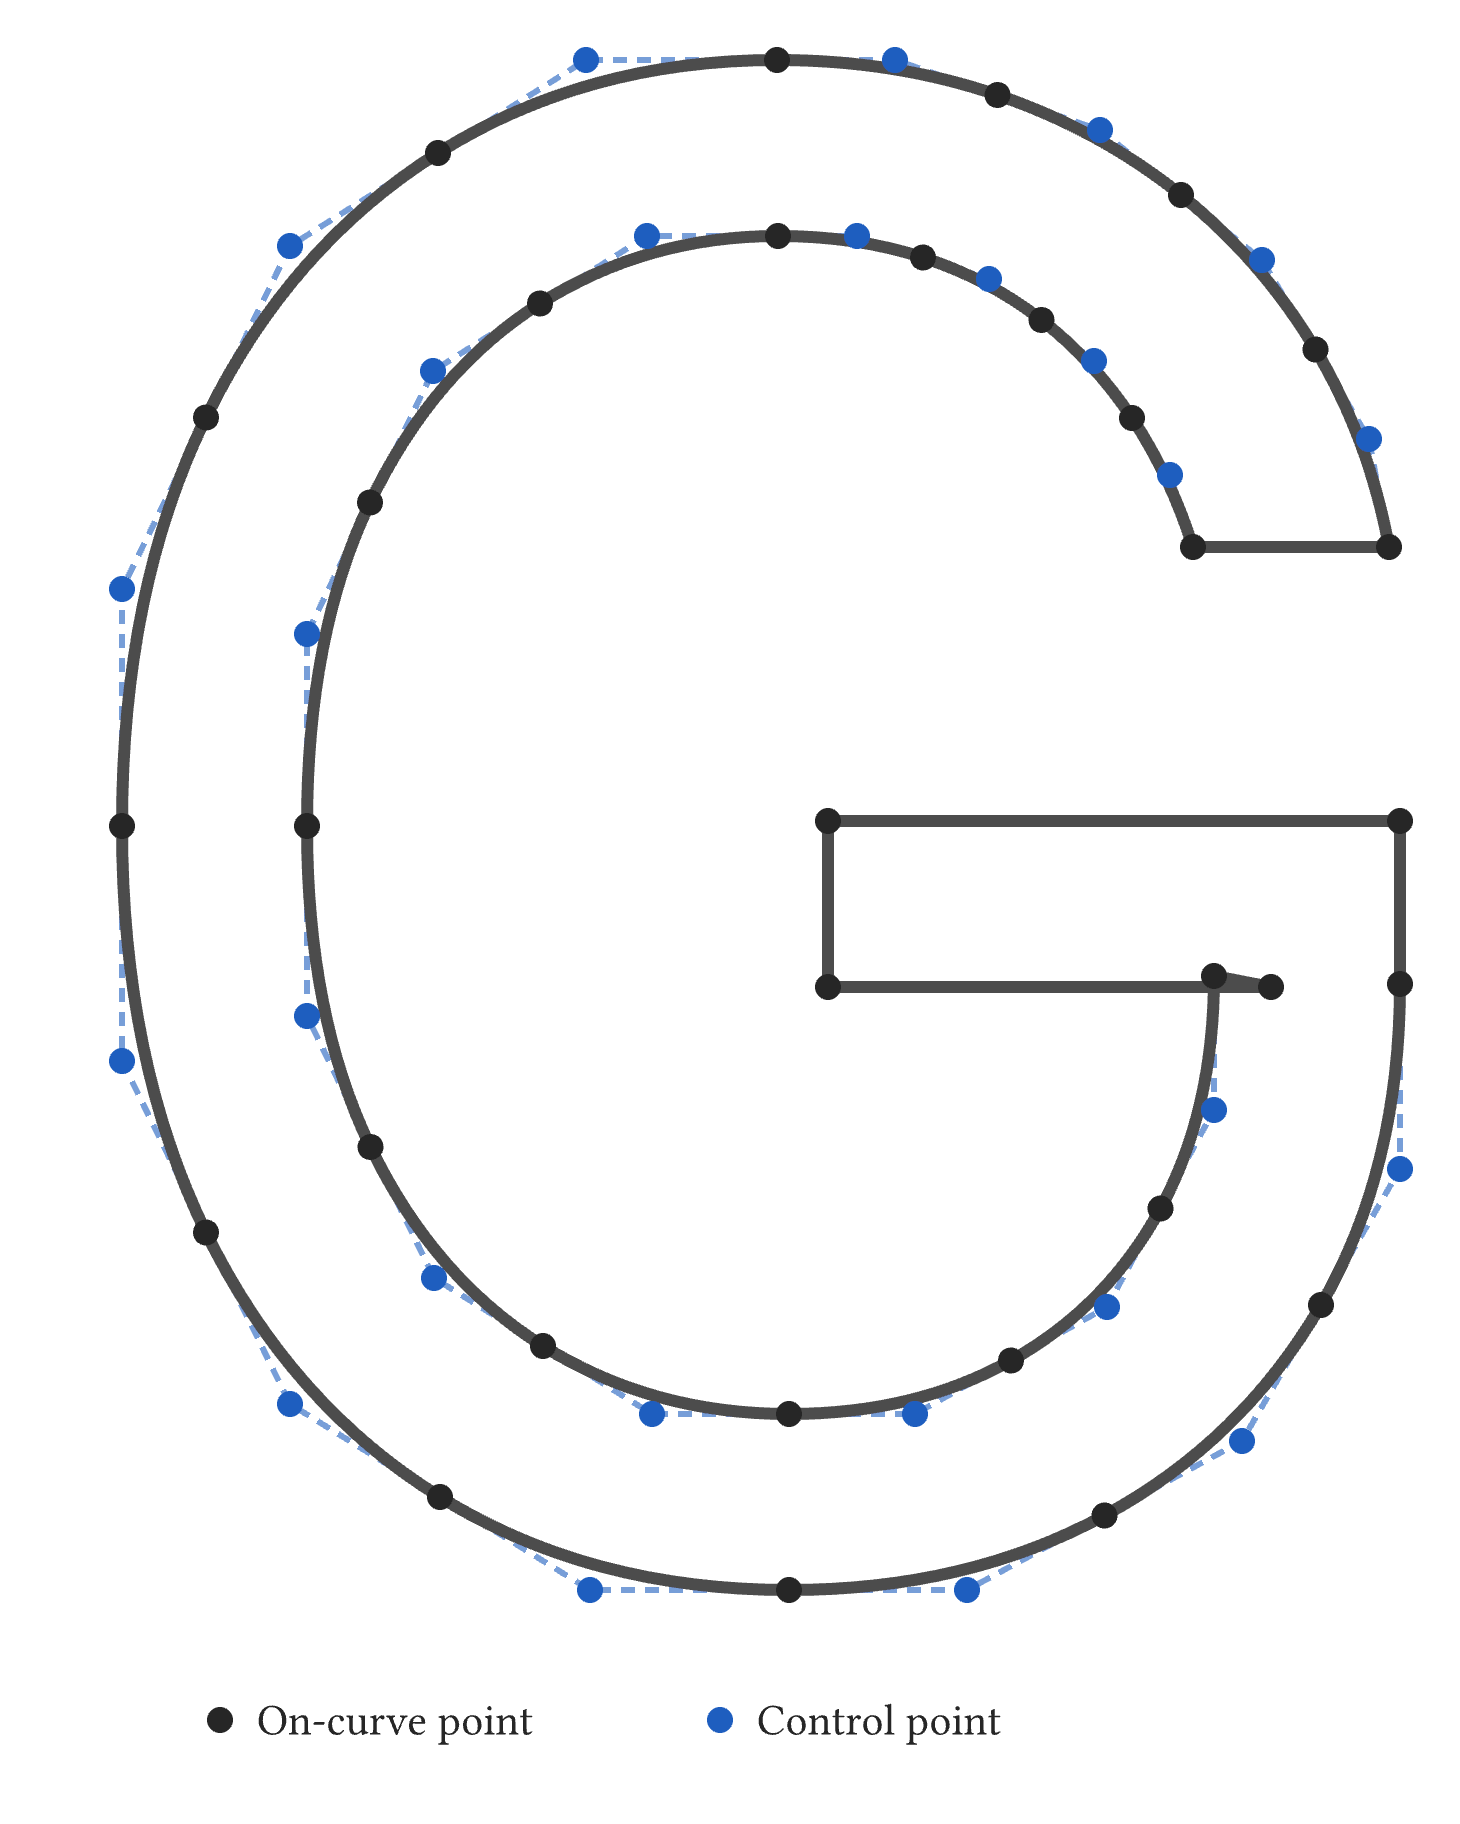

In [4]:
from IPython.display import Image, display

# The working directory is the monorepo root (see the label cell above).
OUTPUT_DIRECTORY = Path("writing/graphics/chapters/font/assets/g-outline")

composition = brushcue.Composition.painter(painter)
image_bytes = composition.execute(ctx).to_image_bytes(ctx)
OUTPUT_DIRECTORY.mkdir(parents=True, exist_ok=True)
(OUTPUT_DIRECTORY / "g_outline.png").write_bytes(image_bytes)
display(Image(image_bytes))